In [1]:
# Час виконання кожної клітинки: записується автоматично, підсумок — у кінці ноутбука
import time as _time
from IPython import get_ipython

_cell_log = []


def _before(info):
    globals()["_cell_start"] = (_time.time(), (info.raw_cell.strip().splitlines() or [""])[0][:70])


def _after(result):
    start, first_line = globals().get("_cell_start", (_time.time(), ""))
    _cell_log.append((len(_cell_log) + 1, round(_time.time() - start, 1), first_line))


get_ipython().events.register("pre_run_cell", _before)
get_ipython().events.register("post_run_cell", _after)

# Демо 1. Ембединги й семантичний пошук

У цьому ноутбуці перетворюємо тексти на **ембединги**. Ембединги — це вектори, у які перетворюються тексти таким чином, що близькі за значенням тексти мають вектори близькі за розміщенням у векторному просторі. На базі цієї властивості будуємо семантичний пошук. З метою навчання робимо це без жодних спеціалізованих бібліотек,
використовуємо лише `numpy`.

Документи для пошуку — нормативні документи Житомирської політехніки з [docs.ztu.edu.ua](https://docs.ztu.edu.ua/):
положення про оцінювання, гуртожитки, стипендії, старосту академічної групи тощо.
Мовна модель, яка потім буде використовуватися для генерації, швидше за все не бачила цих документів під час тренування, тому відповісти на питання про них
вона зможе лише тоді, коли потрібний фрагмент документа буде знайдено й передано їй у промпті.
Пошук потрібних фрагментів документа і є першою половиною RAG.

_Зверніть увагу: ноутбук працює і на CPU, але з GPU ембединги рахуються швидше._

In [2]:
# sentence-transformers — бібліотека для обчислення ембедингів текстів, pypdf — витягування тексту з PDF
!pip install -q "sentence-transformers>=5" pypdf

In [3]:
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")

Пристрій: cuda


## 1. Модель ембедингів

Для перетворення текстових фрагментів на ембединги використовують спеціальні ембедингові моделі. [Qwen3-Embedding-0.6B](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B) — багатомовна модель ембедингів із сімʼї моделей Qwen3. Вона перетворює текст довжиною до ~32 тис. токенів на вектор
із 1024 чисел. Ці два числа: максимальний розмір вхідного тексту і розмірність результуючого ембедингу - є важливими характеристиками ембедингових моделей.

In [4]:
EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-0.6B"
dtype = torch.float16 if device == "cuda" else torch.float32
model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=device, model_kwargs={"dtype": dtype})

print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")
print(f"Максимальна довжина тексту в токенах: {model.max_seq_length}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.2k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

... (6 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

Розмірність ембедингу: 1024
Максимальна довжина тексту в токенах: 32768


/tmp/ipykernel_3155/1793327947.py:5: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")


## 2. Ембединг одного речення

Незалежно від довжини тексту модель повертає вектор однакової розмірності.
Параметр `normalize_embeddings=True` ділить вектор на його евклідову ($L_{2}$) норму. Формула евклідової норми:

$$
\|\vec{x}\|_{2} = \sqrt{\sum_{i=1}^{n}x_{i}^{2}}
$$


Таким чином довжина (норма) вектора дорівнює 1.
Так косинусна подібність, яку потім потрібно часто підраховувати, зводиться до скалярного добутку.

In [5]:
sentence = "Чому я такий розумний?"
embedding = model.encode(sentence, normalize_embeddings=True)

print(f"Форма: {embedding.shape}")
print(f"Перші 8 чисел: {embedding[:8]}")
print(f"Евклідова норма вектора: {np.linalg.norm(embedding):.4f}")

# Загалом модель сама нормалізує вектор всередині,
# тому `normalize_embeddings=True` є зайвим у цьому конкретному випадку
# зверніть увагу на останній шар моделі
print(model)

Форма: (1024,)
Перші 8 чисел: [-0.02551   -0.09235   -0.0002925  0.02061    0.007275   0.0573
 -0.0488     0.04395  ]
Евклідова норма вектора: 1.0000
SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'Qwen3Model'})
  (1): Pooling({'embedding_dimension': 1024, 'pooling_mode': 'lasttoken', 'include_prompt': True})
  (2): Normalize({})
)


## 3. Косинусна подібність

Близькість двох ембедингів вимірюють **косинусом кута** між ними:

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

Значення `1` означає однаковий напрям векторів, `0` — ортогональні вектори, `-1` - вектори вказують у повністю протилежні сторони.
Для нормалізованих векторів знаменник дорівнює 1, і косинус дорівнює скалярному добутку.
Порахуємо його вручну й порівняємо з вбудованим методом `model.similarity`.

In [6]:
a, b, c = model.encode(
    ["Скільки коштує проживання в гуртожитку?",
     "Яка плата за місце в студентському гуртожитку?",
     "Чому Політехніка краще за Гарвард?"],
    normalize_embeddings=True,
)

manual = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
with_library = model.similarity(a, b).item()

print(f"Вручну (a <=> b):     {manual:.4f}")
print(f"Бібліотека (a <=> b): {with_library:.4f}")

print(f"Бібліотека (a <=> c): {model.similarity(a, c).item():.4f}")

Вручну (a <=> b):     0.6489
Бібліотека (a <=> b): 0.6489
Бібліотека (a <=> c): 0.2329


In [7]:
# Оскільки, як зазначалося вище, ембединги є зазвичай нормалізованими векторами, то знаменник дорівнює `1`.
# Перевіримо це:
print(f"Норма a: {np.linalg.norm(a):.4f}")
print(f"Норма b: {np.linalg.norm(b):.4f}")
print(f"Норма c: {np.linalg.norm(c):.4f}")

Норма a: 1.0000
Норма b: 1.0000
Норма c: 1.0000


In [8]:
# Зважаючи на це ми можемо опускати нижню частину формули косинусної подібності
# і вираховувати її лише як скалярний добуток двох векторів

pure_dot_product = np.dot(a, b)
vector_norm_product = np.linalg.norm(a) * np.linalg.norm(b)

assert round(pure_dot_product, 4) == round(manual, 4) == round(with_library, 4), "The teacher made a mistake!"
assert np.isclose(vector_norm_product, 1), "The teacher doesn't know math"

### Косинусна подібність на простих векторах

Ембединг має 1024 виміри, але формула однакова для будь-якої розмірності.
Розглянемо її на двовимірних векторах, які можна намалювати. Вектор $a = (3, 1)$ порівнюємо з чотирма іншими:
- $e = (6, 2)$ — той самий напрям, але вдвічі довший;
- $b = (2, 2)$ — близький напрям;
- $c = (-1, 3)$ — перпендикулярний напрям;
- $d = (-3, -1)$ — протилежний напрям.

a·e =   20   ‖a‖·‖e‖ = 20.00   cos =  1.00   кут =   0.0°
a·b =    8   ‖a‖·‖b‖ =  8.94   cos =  0.89   кут =  26.6°
a·c =    0   ‖a‖·‖c‖ = 10.00   cos =  0.00   кут =  90.0°
a·d =  -10   ‖a‖·‖d‖ = 10.00   cos = -1.00   кут = 180.0°


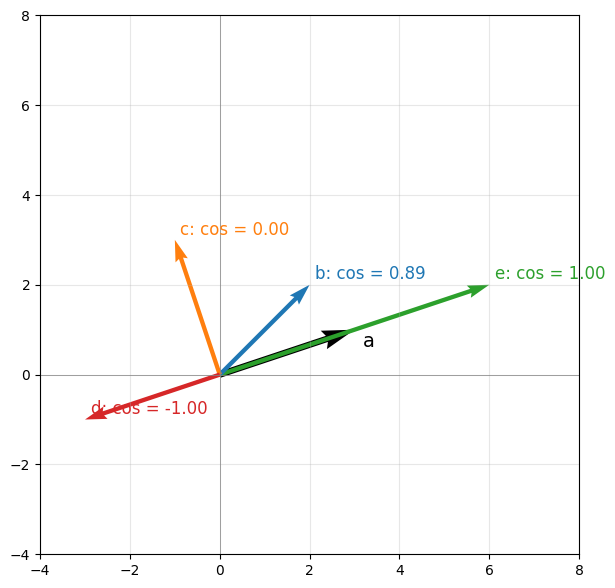

In [9]:
a2 = np.array([3, 1])
others = {
    "e": np.array([6, 2]),
    "b": np.array([2, 2]),
    "c": np.array([-1, 3]),
    "d": np.array([-3, -1]),
}


def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))


for name, v in others.items():
    dot = np.dot(a2, v)
    norms = np.linalg.norm(a2) * np.linalg.norm(v)
    angle = np.degrees(np.arccos(np.clip(cosine(a2, v), -1, 1)))
    print(f"a·{name} = {dot:4}   ‖a‖·‖{name}‖ = {norms:5.2f}   cos = {dot / norms:5.2f}   кут = {angle:5.1f}°")

fig, ax = plt.subplots(figsize=(7, 7))
ax.quiver(0, 0, *a2, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(f"{name}: cos = {cosine(a2, v):.2f}", v, xytext=(4, 4), textcoords="offset points",
                fontsize=12, color=color)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-4, 8)
ax.set_ylim(-4, 8)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Косинус залежить лише від кута між векторами, а не від їхньої довжини: вектор $e$ удвічі довший за $a$,
але косинус дорівнює 1. Знаменник формули саме й прибирає вплив довжини.

Тепер нормалізуємо всі вектори — поділимо кожен на його довжину. Кінці нормалізованих векторів лежать
на колі радіуса 1, напрями не змінюються, а скалярний добуток дорівнює косинусу без жодного ділення.

e = [0.949 0.316]   довжина = 1.00   скалярний добуток =  1.00   cos =  1.00
b = [0.707 0.707]   довжина = 1.00   скалярний добуток =  0.89   cos =  0.89
c = [-0.316  0.949]   довжина = 1.00   скалярний добуток =  0.00   cos =  0.00
d = [-0.949 -0.316]   довжина = 1.00   скалярний добуток = -1.00   cos = -1.00


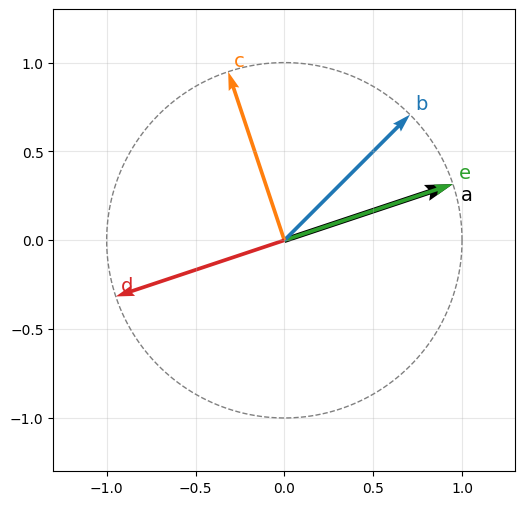

In [10]:
def normalize(v):
    return v / np.linalg.norm(v)


a2_unit = normalize(a2)
for name, v in others.items():
    v_unit = normalize(v)
    print(f"{name} = {np.round(v_unit, 3)}   довжина = {np.linalg.norm(v_unit):.2f}   "
          f"скалярний добуток = {np.dot(a2_unit, v_unit):5.2f}   cos = {cosine(a2, v):5.2f}")

fig, ax = plt.subplots(figsize=(6, 6))
circle = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(circle), np.sin(circle), color="grey", lw=1, ls="--")
ax.quiver(0, 0, *a2_unit, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2_unit, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    v_unit = normalize(v)
    ax.quiver(0, 0, *v_unit, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(name, v_unit, xytext=(4, 4), textcoords="offset points", fontsize=14, color=color)
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Вектори $a$ і $e$ після нормалізації збіглися: однаковий напрям — однаковий нормалізований вектор.

### Три виміри

У трьох вимірах усе так само: кожна компонента вектора — окрема вісь, скалярний добуток — сума
трьох попарних добутків. Нехай компоненти означають, наскільки текст стосується трьох тем:
гуртожитку, стипендії й погоди.

«плата за гуртожиток» і «заселення в гуртожиток»: a·b = 0.9·0.8 + 0.3·0.1 + 0.0·0.1 = 0.75, cos = 0.97
«плата за гуртожиток» і «стипендія»: a·b = 0.9·0.2 + 0.3·0.9 + 0.0·0.0 = 0.45, cos = 0.51
«плата за гуртожиток» і «погода»: a·b = 0.9·0.0 + 0.3·0.1 + 0.0·0.9 = 0.03, cos = 0.03


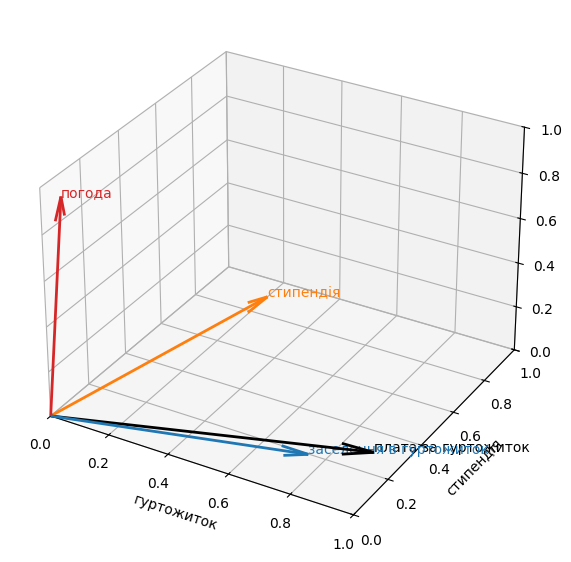

In [11]:
vectors_3d = {
    "плата за гуртожиток": np.array([0.9, 0.3, 0.0]),
    "заселення в гуртожиток": np.array([0.8, 0.1, 0.1]),
    "стипендія": np.array([0.2, 0.9, 0.0]),
    "погода": np.array([0.0, 0.1, 0.9]),
}
names_3d = list(vectors_3d)
query_3d = vectors_3d[names_3d[0]]
for name in names_3d[1:]:
    v = vectors_3d[name]
    products = " + ".join(f"{x:.1f}·{y:.1f}" for x, y in zip(query_3d, v))
    print(f"«{names_3d[0]}» і «{name}»: a·b = {products} = {np.dot(query_3d, v):.2f}, cos = {cosine(query_3d, v):.2f}")

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
for (name, v), color in zip(vectors_3d.items(), ["black", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, 0, *v, color=color, arrow_length_ratio=0.1, linewidth=2)
    ax.text(*v, name, color=color, fontsize=10)
ax.set_xlabel("гуртожиток")
ax.set_ylabel("стипендія")
ax.set_zlabel("погода")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 1)
plt.show()

Справжній ембединг влаштований так само, лише замість трьох осей — 1024. На відміну від цього прикладу,
окремі виміри ембединга не мають зрозумілого людині змісту: значення має лише напрям вектора в цілому.

## 4. Матриця подібності

Порахуємо подібність кожного речення з кожним. Серед речень є:
- дві пари перефразувань (про плату за гуртожиток і про стипендію);
- два речення зі спільним словом «ключ», але різним змістом;
- речення, не повʼязане з рештою.

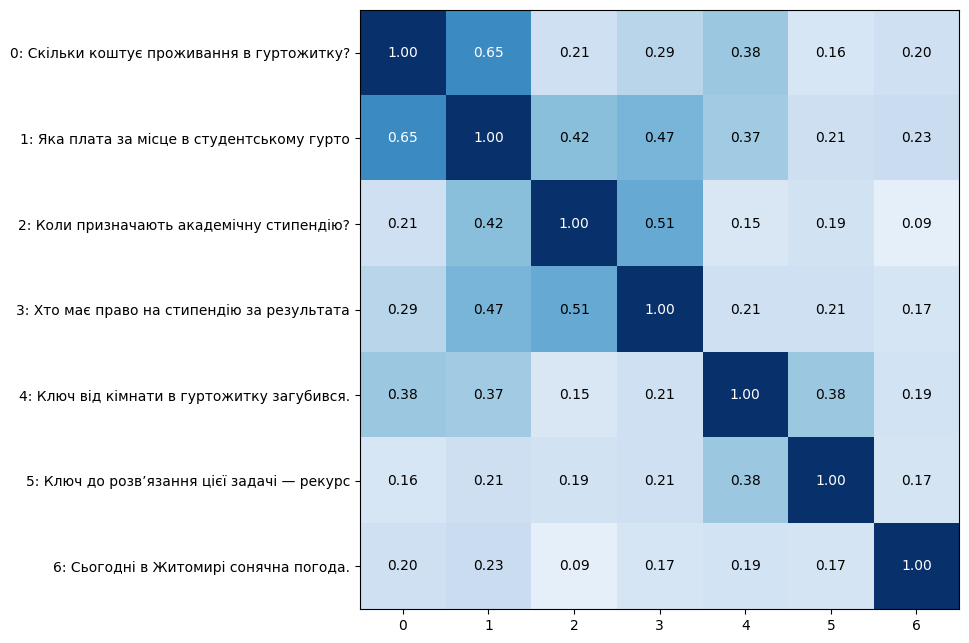

In [12]:
def show_similarity_matrix(sentences, figsize=(9, 7)):
  embeddings = model.encode(sentences, normalize_embeddings=True)
  similarity = embeddings @ embeddings.T

  fig, ax = plt.subplots(figsize=figsize)
  ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
  ax.set_xticks(range(len(sentences)), [f"{i}" for i in range(len(sentences))])
  ax.set_yticks(range(len(sentences)), [f"{i}: {s[:40]}" for i, s in enumerate(sentences)])
  for i in range(len(sentences)):
      for j in range(len(sentences)):
          ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center",
                  color="white" if similarity[i, j] > 0.6 else "black")
  plt.tight_layout()
  plt.show()

uni_sentences = [
    "Скільки коштує проживання в гуртожитку?",
    "Яка плата за місце в студентському гуртожитку?",
    "Коли призначають академічну стипендію?",
    "Хто має право на стипендію за результатами сесії?",
    "Ключ від кімнати в гуртожитку загубився.",
    "Ключ до розвʼязання цієї задачі — рекурсія.",
    "Сьогодні в Житомирі сонячна погода.",
]

show_similarity_matrix(uni_sentences)


### Власні речення (питання 5)

Додано: перефразування речення 2, речення зі спільним словом «плата», але іншим змістом, і заперечення речення 4.

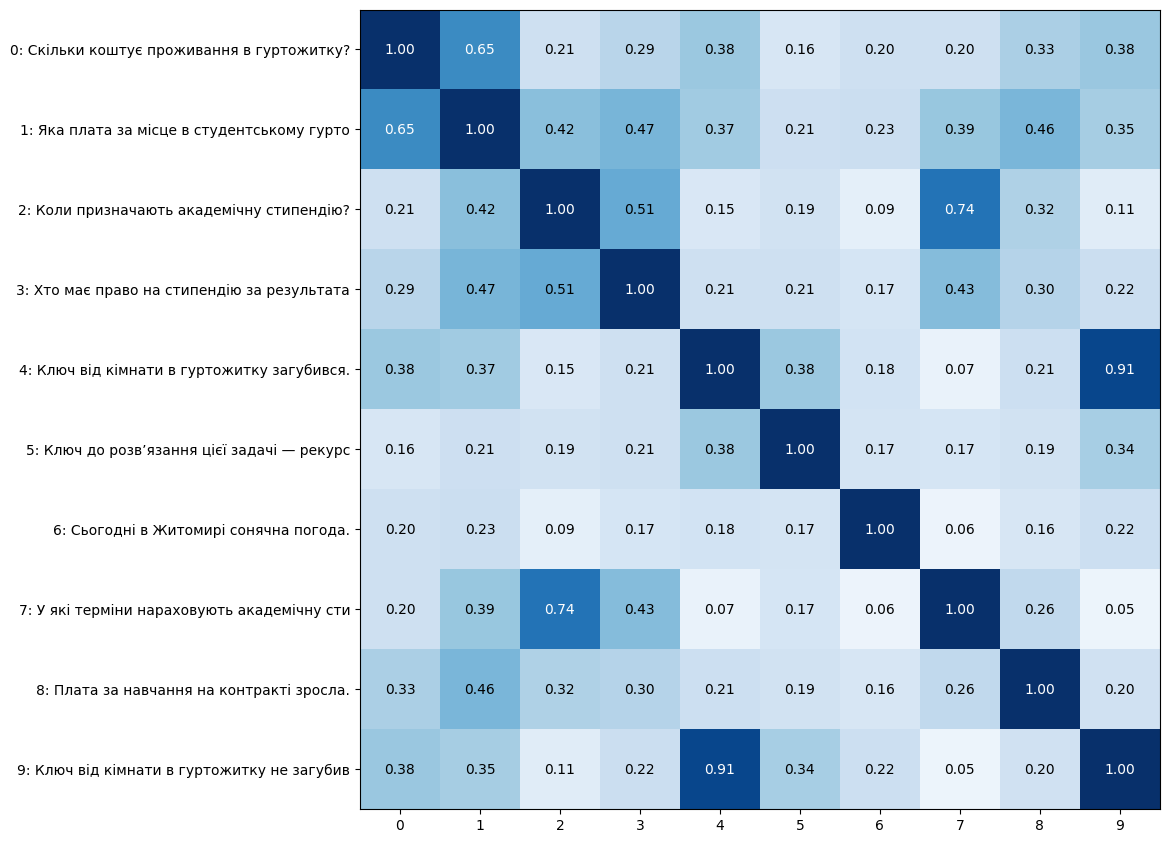

In [13]:
my_sentences = uni_sentences + [
    "У які терміни нараховують академічну стипендію?",
    "Плата за навчання на контракті зросла.",
    "Ключ від кімнати в гуртожитку не загубився.",
]
show_similarity_matrix(my_sentences, figsize=(11, 9))

Перефразування мають найвищу подібність, хоча містять лише одне спільне слово, так само як і пара з речень 4-5, схожість яких вдвічі менша.
Водночас подібність ніколи не падає до нуля: навіть речення про погоду має з рештою додатну подібність.

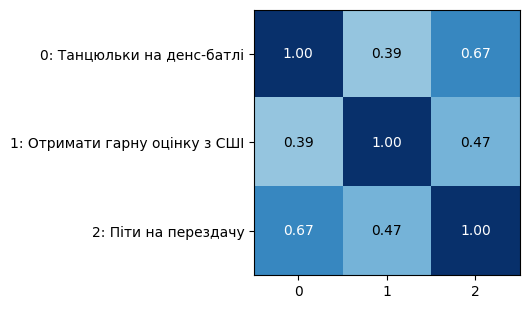

In [14]:
# Пограємося, вимірюючи подібність цілком випадкових і взагалі не придуманих викладачем фраз

pseudo_random_sentences = [
    "Танцюльки на денс-батлі",
    "Отримати гарну оцінку з СШІ",
    "Піти на перездачу"
]

show_similarity_matrix(pseudo_random_sentences, figsize=(5, 4))


### Інша модель ембедингів (питання 6)

In [15]:
other_model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device=device)
other = other_model.encode(pseudo_random_sentences, normalize_embeddings=True)
qwen = model.encode(pseudo_random_sentences, normalize_embeddings=True)
for name, emb in [("Qwen3-Embedding-0.6B", qwen), ("paraphrase-multilingual-MiniLM-L12-v2", other)]:
    sim = emb @ emb.T
    print(f"{name}:")
    for i in range(len(pseudo_random_sentences)):
        for j in range(i + 1, len(pseudo_random_sentences)):
            print(f"  {pseudo_random_sentences[i]} <=> {pseudo_random_sentences[j]}: {sim[i, j]:.2f}")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Qwen3-Embedding-0.6B:
  Танцюльки на денс-батлі <=> Отримати гарну оцінку з СШІ: 0.39
  Танцюльки на денс-батлі <=> Піти на перездачу: 0.67
  Отримати гарну оцінку з СШІ <=> Піти на перездачу: 0.47
paraphrase-multilingual-MiniLM-L12-v2:
  Танцюльки на денс-батлі <=> Отримати гарну оцінку з СШІ: 0.07
  Танцюльки на денс-батлі <=> Піти на перездачу: 0.50
  Отримати гарну оцінку з СШІ <=> Піти на перездачу: 0.33


## 5. Тексти на площині

Вектор із 1024 чисел неможливо намалювати, тому проєктуємо ембединги на площину методом головних компонент (Principal Component Analysis, PCA).
Проєкція втрачає більшу частину інформації, але групи речень на одну тему видно й на ній.

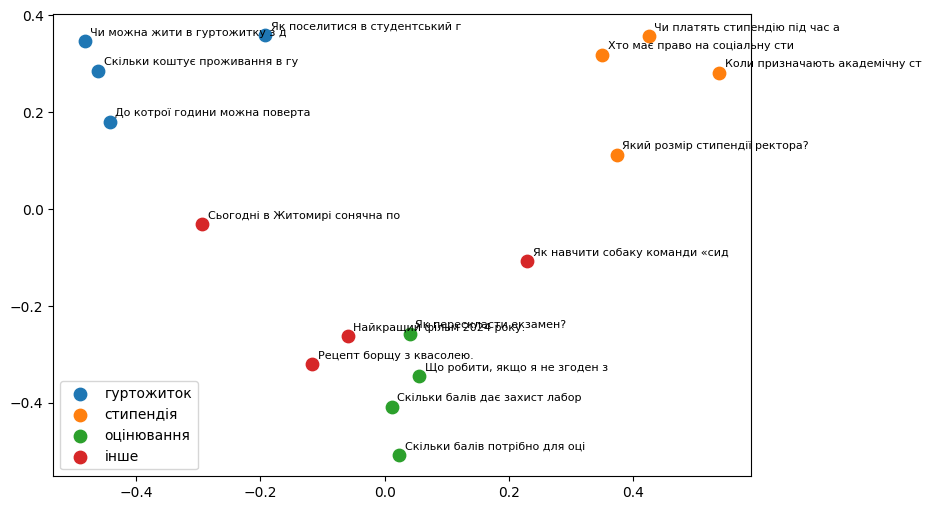

In [16]:
topics = {
    "гуртожиток": [
        "Скільки коштує проживання в гуртожитку?",
        "Як поселитися в студентський гуртожиток?",
        "До котрої години можна повертатися в гуртожиток?",
        "Чи можна жити в гуртожитку з дружиною?",
    ],
    "стипендія": [
        "Коли призначають академічну стипендію?",
        "Хто має право на соціальну стипендію?",
        "Який розмір стипендії ректора?",
        "Чи платять стипендію під час академічної відпустки?",
    ],
    "оцінювання": [
        "Скільки балів потрібно для оцінки «відмінно»?",
        "Що робити, якщо я не згоден з оцінкою?",
        "Як перескласти екзамен?",
        "Скільки балів дає захист лабораторної роботи?",
    ],
    "інше": [
        "Сьогодні в Житомирі сонячна погода.",
        "Рецепт борщу з квасолею.",
        "Найкращий фільм 2024 року.",
        "Як навчити собаку команди «сидіти»?",
    ],
}
texts = [t for group in topics.values() for t in group]
labels = [name for name, group in topics.items() for _ in group]
# На GPU модель працює у float16, а SVD у numpy підтримує лише float32 і float64
points = model.encode(texts, normalize_embeddings=True).astype(np.float32)

centered = points - points.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
xy = centered @ vt[:2].T

fig, ax = plt.subplots(figsize=(9, 6))
for name in topics:
    mask = np.array(labels) == name
    ax.scatter(xy[mask, 0], xy[mask, 1], s=80, label=name)
for (x, y), t in zip(xy, texts):
    ax.annotate(t[:30], (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.legend()
plt.show()

## 6. Запит і документ кодуються по-різному

Короткий запит («до якої дати платити?») і фрагмент документа, що містить відповідь, — тексти різного вигляду.
Тому багато моделей ембедингів додають до запиту інструкцію. Qwen3-Embedding зберігає її у промпті `query`,
а документи кодує без інструкції.

In [17]:
print(repr(model.prompts["query"]))
print(repr(model.prompts["document"]))

'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'
''


In [18]:
passages = [
    "Студент вносить авансовий платіж за 1 семестр до 1 вересня, а за 2 семестр – до 1 лютого.",
    "З 23:00 години і до 7:00 години в гуртожитку повинна додержуватись тиша.",
    "Вибори старости академічної групи на 1 курсі відбуваються після двох тижнів навчального процесу.",
    "Оцінка «добре» (B за шкалою ЄКТС) відповідає 82–89 балам.",
]
queries = [
    "До якої дати платити за гуртожиток?",
    "Коли в гуртожитку не можна шуміти?",
    "Коли обирають старосту?",
    "Скільки балів на B?",
]
passage_embeddings = model.encode(passages, normalize_embeddings=True)

np.set_printoptions(precision=2, suppress=True)
for prompt_name in [None, "query"]:
    query_embeddings = model.encode(queries, normalize_embeddings=True, prompt_name=prompt_name)
    print(f"Промпт запиту: {prompt_name}")
    print(query_embeddings @ passage_embeddings.T, "\n")

Промпт запиту: None
[[0.44 0.52 0.28 0.15]
 [0.17 0.69 0.22 0.15]
 [0.15 0.11 0.43 0.15]
 [0.2  0.16 0.16 0.38]] 

Промпт запиту: query
[[0.51 0.61 0.33 0.18]
 [0.2  0.76 0.24 0.15]
 [0.2  0.14 0.45 0.17]
 [0.19 0.17 0.17 0.4 ]] 



Рядки — запити, стовпці — фрагменти; на діагоналі стоїть правильна пара.

## 7. Документи університету

Завантажуємо 14 документів із сайту університету й витягуємо з них текст бібліотекою `pypdf`.
Серед них дві версії Положення про оцінювання — чинна і стара — та дві редакції освітньої програми
«Інженерія програмного забезпечення». Такі дублікати з різними даними типові для реальних баз документів.

In [19]:
BASE_URL = "https://docs.ztu.edu.ua/"
DOCUMENTS = [
    ("275", "Положення про оцінювання результатів навчання (чинна версія 4.0)", {"mdocs-file": 275}),
    ("275-v3.1", "Положення про оцінювання результатів навчання (стара версія 3.1)",
     {"mdocs-version": "polozhennja pro ocinjuvannja znan yekts_nove.pdf-v3.1", "mdocs-file": 275, "mdocs-url": "false"}),
    ("277", "Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін", {"mdocs-file": 277}),
    ("291", "Положення про проведення практики здобувачів вищої освіти", {"mdocs-file": 291}),
    ("340", "Правила призначення академічних стипендій", {"mdocs-file": 340}),
    ("344", "Положення про стипендію ректора", {"mdocs-file": 344}),
    ("348", "Положення про користування гуртожитками", {"mdocs-file": 348}),
    ("1219", "Правила внутрішнього розпорядку в студентських гуртожитках", {"mdocs-file": 1219}),
    ("1199", "Кодекс академічної доброчесності", {"mdocs-file": 1199}),
    ("4389", "Положення про студентського омбудсмана", {"mdocs-file": 4389}),
    ("336", "Положення про старосту академічної групи", {"mdocs-file": 336}),
    ("3320", "ОПП F2 «Інженерія програмного забезпечення» (бакалавр), редакція 2025 року", {"mdocs-file": 3320}),
    ("3329", "ОПП 121 «Інженерія програмного забезпечення» (бакалавр), редакція 2024 року", {"mdocs-file": 3329}),
    ("283", "Положення про переведення здобувачів вищої освіти", {"mdocs-file": 283}),
]


PDF_DIR = Path("ztu_pdfs")
PDF_DIR.mkdir(exist_ok=True)


def fetch(params, attempts=3):
    # Сайт іноді обриває зʼєднання, тому пробуємо кілька разів
    for attempt in range(attempts):
        try:
            response = requests.get(BASE_URL, params=params, timeout=120)
            response.raise_for_status()
            return response.content
        except requests.RequestException:
            if attempt == attempts - 1:
                raise
            time.sleep(5)


def download_pdf(doc_id, params):
    # Зберігаємо PDF на диск, щоб під час повторного запуску не завантажувати їх знову
    path = PDF_DIR / f"{doc_id}.pdf"
    if not path.exists():
        path.write_bytes(fetch(params))
    return PdfReader(path)

### Колонтитули

Кожна сторінка цих документів починається з однакового колонтитула системи управління якістю
(назва університету, код документа, номер аркуша). Прибираємо рядки колонтитула регулярним виразом.
Оформлення колонтитула в різних документах трохи відрізняється (регістр, формат коду документа), тому вираз
нечутливий до регістру й перевіряє лише перші 12 рядків сторінки, щоб не зачепити числа в таблицях.

In [20]:
HEADER_LINE = re.compile(
    r"^(Житомирська|політехніка|Міністерство освіти.*|Державний університет «Житомирська політехніка»|"
    r"Система управління якістю.*|П[\s\-–]*[CС]?[АA]?[ГG]?[\s\d.\-–]*|[\d.\-–\s/_]+|Випуск.*)$",
    re.IGNORECASE,
)
HEADER_LINES = 12


def page_text(page):
    lines = (page.extract_text() or "").split("\n")
    head = [line for line in lines[:HEADER_LINES] if not HEADER_LINE.match(line.strip())]
    return " ".join(head + lines[HEADER_LINES:])


reader = download_pdf("336", {"mdocs-file": 336})
print("До очищення:\n", reader.pages[2].extract_text()[:400])
print("\nПісля очищення:\n", page_text(reader.pages[2])[:400])

До очищення:
 Житомирська 
політехніка 
Міністерство освіти і науки України 
Державний університет «Житомирська політехніка» 
П CАГ – 44 – 15 – 02 – 
2019 
Випуск 2 Зміни 1 Екземпляр № 2 Арк   8/__ 
 
 3 
 
1. ЗАГАЛЬНІ ПОЛОЖЕННЯ 
1.1. Старостою академічної групи може бути студент, якому притаманні високі 
моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив 
на колектив гру

Після очищення:
     1. ЗАГАЛЬНІ ПОЛОЖЕННЯ  1.1. Старостою академічної групи може бути студент, якому притаманні високі  моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив  на колектив групи та володіє організаторськими здібностями.  1.2. Староста студентської академічної групи обирається як представник деканату для  організаційного забезпечення навчального процесу в академі


### Документи без текстового шару

Частина PDF — це відскановані сторінки: замість тексту в них зображення, і `pypdf` нічого не витягує.
Для таких документів потрібне розпізнавання тексту (OCR); у цьому демо ми їх просто пропускаємо.

In [21]:
MIN_CHARS_PER_PAGE = 100


def document_text(reader):
    return re.sub(r"\s+", " ", " ".join(page_text(page) for page in reader.pages)).strip()


def is_scan(text, reader):
    return len(text) < MIN_CHARS_PER_PAGE * len(reader.pages)


documents = {}
for doc_id, title, params in DOCUMENTS:
    reader = download_pdf(doc_id, params)
    text = document_text(reader)
    if is_scan(text, reader):
        print(f"{doc_id}: текстового шару немає, потрібне OCR — пропущено")
        continue
    documents[doc_id] = {"title": title, "text": text}
    print(f"{doc_id}: {len(reader.pages)} сторінок, {len(text)} символів — {title}")

275: 23 сторінок, 24944 символів — Положення про оцінювання результатів навчання (чинна версія 4.0)
275-v3.1: 13 сторінок, 10505 символів — Положення про оцінювання результатів навчання (стара версія 3.1)
277: 16 сторінок, 15945 символів — Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
291: 17 сторінок, 14603 символів — Положення про проведення практики здобувачів вищої освіти
340: 30 сторінок, 35706 символів — Правила призначення академічних стипендій
344: 10 сторінок, 2455 символів — Положення про стипендію ректора
348: 22 сторінок, 25608 символів — Положення про користування гуртожитками
1219: 12 сторінок, 9159 символів — Правила внутрішнього розпорядку в студентських гуртожитках
1199: 37 сторінок, 56918 символів — Кодекс академічної доброчесності
4389: 18 сторінок, 20685 символів — Положення про студентського омбудсмана
336: 8 сторінок, 3560 символів — Положення про старосту академічної групи
3320: 16 сторінок, 31670 символів — ОПП F2 «Інженері

## 8. Пошук вручну

Цілий документ задовгий для одного ембединга: у вектор із 1024 чисел не вміститься зміст 30 сторінок.
Тому ділимо кожен документ на **фрагменти** по 1000 символів, що перекриваються на 200 символів,
щоб речення на межі потрапило хоча б в один фрагмент повністю. Зверніть увагу, це не є найоптимальнішим способом для таких документів. Способи розбиття детально розглядаємо в демо 2.

In [22]:
CHUNK_SIZE, OVERLAP = 1000, 200

chunks = []
for doc_id, doc in documents.items():
    text = doc["text"]
    for start in range(0, len(text), CHUNK_SIZE - OVERLAP):
        chunks.append({"doc_id": doc_id, "text": text[start:start + CHUNK_SIZE]})

print(f"Фрагментів: {len(chunks)}")
start = time.time()
chunk_embeddings = model.encode([c["text"] for c in chunks], normalize_embeddings=True,
                                batch_size=16, show_progress_bar=True)
print(f"Ембединги пораховано за {time.time() - start:.1f} с, форма матриці: {chunk_embeddings.shape}")

Фрагментів: 361


Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Ембединги пораховано за 17.7 с, форма матриці: (361, 1024)


Увесь пошук — це одне множення матриці фрагментів на вектор запиту й сортування результатів.

In [23]:
def search(query, embeddings, k=3):
    query_embedding = model.encode(query, normalize_embeddings=True, prompt_name="query")
    scores = embeddings @ query_embedding
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top]


def show(query, embeddings, k=3):
    print(f"Запит: {query}")
    for i, score in search(query, embeddings, k):
        chunk = chunks[i]
        print(f"  {score:.2f}  [{chunk['doc_id']}] {documents[chunk['doc_id']]['title']}")
        print(f"        {chunk['text'][:150]}…")
    print()


show("Коли обирають старосту на першому курсі?", chunk_embeddings)
show("Хто такий студентський омбудсман?", chunk_embeddings)

Запит: Коли обирають старосту на першому курсі?
  0.57  [336] Положення про старосту академічної групи
         ректоратом або за їх дорученням. У своїй роботі староста академічної групи співпрацює з куратором та ментором групи. 1.3. У виборах старости студентс…
  0.50  [4389] Положення про студентського омбудсмана
        ємодіє з Молодіжною радою при Житомирській обласній державній (військовій) адміністрації та іншими консультативно-дорадчими органами молодіжної політи…
  0.50  [277] Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
        нсульт Максим ОСТАПЧУК __.__.20__ Додаток 1 до Положення про порядок та умови обрання здобувачами вищої освіти вибіркових дисциплін (пункт 2.4.) Декан…

Запит: Хто такий студентський омбудсман?
  0.71  [4389] Положення про студентського омбудсмана
        ЗАТВЕРДЖЕНО Наказ Державного університету «Житомирська політехніка» 28 вересня 2026 р. № 453/од ПОЛОЖЕННЯ про студентського омбудсмана у Державному ун…
  0.71  

### Питання з відомими відповідями

Для кожного питання ми заздалегідь знаємо документ, у якому є відповідь.
Перевіримо, чи потрапляє фрагмент із цього документа до трьох найближчих.

In [24]:
QUESTIONS = [
    ("До якої дати потрібно оплатити гуртожиток за перший семестр?", "348"),
    ("Чи можна платити за гуртожиток щомісяця?", "348"),
    ("Чи можна жити в гуртожитку з дружиною?", "348"),
    ("З якої години в гуртожитку має бути тиша?", "1219"),
    ("Коли обирають старосту на першому курсі?", "336"),
    ("Скільки балів потрібно для оцінки «добре» B?", "275"),
    ("Що робити, якщо я не згоден з оцінкою за семестр?", "275"),
    ("Яку частку кредитів становлять вибіркові дисципліни?", "277"),
    ("Хто такий студентський омбудсман?", "4389"),
]


def check(embeddings, k=3):
    found = 0
    for question, gold in QUESTIONS:
        top_docs = [chunks[i]["doc_id"] for i, _ in search(question, embeddings, k)]
        hit = gold in top_docs
        found += hit
        print(f"{'✓' if hit else '✗'} {question}  очікуємо {gold}, знайдено {top_docs}")
    print(f"\nЗнайдено {found} з {len(QUESTIONS)}")


check(chunk_embeddings)

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['1219', '348', '1219']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '1219', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '277']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '340', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['1199', '275', '340']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '3320', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


Зверніть увагу, з якої версії Положення про оцінювання знайдено фрагменти:
пошук не знає, що версія 3.1 застаріла, і може повернути її поряд із чинною або замість неї.

### Питання, на яке в документах немає відповіді

Пошук завжди повертає `k` найближчих фрагментів, навіть якщо жоден із них не стосується питання.
Подібність у такому випадку нижча, але не нульова, а універсального порогу, нижче якого результат слід відкинути, немає:
він залежить від моделі й корпусу.

In [25]:
show("Скільки коштує обід у студентській їдальні?", chunk_embeddings)

Запит: Скільки коштує обід у студентській їдальні?
  0.51  [348] Положення про користування гуртожитками
        Університету згідно з виставленими рахунками. 5.2. Студент вносить авансовий платіж оплати за 1 семестр (5 місяців), включаючи і час своєї відсутності…
  0.48  [348] Положення про користування гуртожитками
         і тягне за собою виселення без права подальшого заселення. 4.16. За активну участь у культурних заходах, роботах з покращення умов проживання, стану …
  0.45  [340] Правила призначення академічних стипендій
        ться на загальних підставах відповідно до законодавства. У разі коли особі призначена академічна стипендія, здійснюється перерахунок коштів та виплата…



### Власні питання (питання 9)

In [26]:
MY_QUESTIONS = [
    ("Хто може отримувати стипендію ректора?", "344"),
    ("Скільки разів можна перескладати підсумковий контроль?", "275"),
    ("Як перевестися на іншу спеціальність?", "283"),
]
for question, gold in MY_QUESTIONS:
    results = search(question, chunk_embeddings, k=3)
    top_docs = [chunks[i]["doc_id"] for i, _ in results]
    print(f"{'так' if gold in top_docs else 'ні '} {question}  очікуємо {gold}, знайдено {top_docs}, "
          f"найкраща подібність {results[0][1]:.2f}")
    show(question, chunk_embeddings)

no_answer = search("Скільки коштує обід у студентській їдальні?", chunk_embeddings, k=1)[0][1]
print(f"Найкраща подібність для питання без відповіді: {no_answer:.2f}")

так Хто може отримувати стипендію ректора?  очікуємо 344, знайдено ['344', '340', '344'], найкраща подібність 0.64
Запит: Хто може отримувати стипендію ректора?
  0.64  [344] Положення про стипендію ректора
        ЗМІСТ 1. Загальні положення……………………………….. 3 2. Порядок призначення стипендії………………… 3 ЗМІСТ 1. Загальні положення……………………………….. 3 2. Порядок призначен…
  0.62  [340] Правила призначення академічних стипендій
        ращих з них за успіхи у навчанні, участь у громадській, спортивній і науковій діяльності наказом ректора Житомирської політехніки утворюються стипенді…
  0.59  [344] Положення про стипендію ректора
        ивних досягнень кожного кандидата. 2. Порядок призначення стипендії 2.1. Висування кандидатів на здобуття Стипендії відбувається на зборах студентськи…

так Скільки разів можна перескладати підсумковий контроль?  очікуємо 275, знайдено ['275', '275', '275'], найкраща подібність 0.55
Запит: Скільки разів можна перескладати підсумковий контроль?
  0.55  [275] Пол

## 9. Фрагмент із контекстом

У розділі 6 фрагмент про оплату програв фрагменту про тишу, бо в ньому немає слова «гуртожиток».
Найпростіший спосіб повернути фрагменту контекст — дописати на його початок назву документа.

In [27]:
payment, silence = passages[0], passages[1]
with_titles = [
    f"{documents['348']['title']}. {payment}",
    f"{documents['1219']['title']}. {silence}",
]
query_embedding = model.encode("До якої дати платити за гуртожиток?", normalize_embeddings=True, prompt_name="query")

for name, texts in [("Без назви документа", [payment, silence]), ("З назвою документа", with_titles)]:
    scores = model.encode(texts, normalize_embeddings=True) @ query_embedding
    print(f"{name}: оплата {scores[0]:.2f}, тиша {scores[1]:.2f}")

Без назви документа: оплата 0.51, тиша 0.61
З назвою документа: оплата 0.76, тиша 0.59


In [28]:
titled_embeddings = model.encode([f"{documents[c['doc_id']]['title']}. {c['text']}" for c in chunks],
                                 normalize_embeddings=True, batch_size=16, show_progress_bar=True)
check(titled_embeddings)

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['348', '348', '348']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '348', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '336']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '275', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['275', '275', '275']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '277', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


### Фрагменти, що без назви документа втрачають зміст (питання 10)

Для кожного питання — ранг першого фрагмента з правильного документа без назви і з назвою.

In [29]:
def gold_rank(question, gold, embeddings):
    for rank, (i, _) in enumerate(search(question, embeddings, k=len(chunks)), start=1):
        if chunks[i]["doc_id"] == gold:
            return rank, i


for question, gold in QUESTIONS:
    plain_rank, _ = gold_rank(question, gold, chunk_embeddings)
    titled_rank, i = gold_rank(question, gold, titled_embeddings)
    print(f"{plain_rank:>3} → {titled_rank:<3} {question}")
    if plain_rank > 3 >= titled_rank:
        print(f"      фрагмент [{chunks[i]['doc_id']}]: {chunks[i]['text'][:300]}…")

  1 → 1   До якої дати потрібно оплатити гуртожиток за перший семестр?
  1 → 1   Чи можна платити за гуртожиток щомісяця?
  2 → 1   Чи можна жити в гуртожитку з дружиною?
  1 → 1   З якої години в гуртожитку має бути тиша?
  1 → 1   Коли обирають старосту на першому курсі?
  3 → 2   Скільки балів потрібно для оцінки «добре» B?
  2 → 1   Що робити, якщо я не згоден з оцінкою за семестр?
  1 → 1   Яку частку кредитів становлять вибіркові дисципліни?
  1 → 1   Хто такий студентський омбудсман?


## Підсумок

- Модель ембедингів перетворює текст будь-якої довжини на вектор фіксованої розмірності.
- Близькість текстів вимірюють косинусною подібністю; для нормалізованих векторів це скалярний добуток.
- Семантичний пошук — множення матриці ембедингів фрагментів на ембединг запиту й вибір `k` найбільших значень.
- Пошук повертає результат навіть тоді, коли відповіді в документах немає.
- Фрагмент, вирваний із документа, втрачає контекст; назва документа на початку фрагмента частково його повертає.

## Час виконання клітинок

In [30]:
import pandas as pd

timing = pd.DataFrame(_cell_log, columns=["клітинка", "секунд", "перший рядок"])
print(f"Усього: {timing['секунд'].sum() / 60:.1f} хв")
timing.sort_values("секунд", ascending=False).head(10)

Усього: 2.9 хв


,клітинка,секунд,перший рядок
20,21,42.9,MIN_CHARS_PER_PAGE = 100
2,3,38.8,import re
3,4,28.1,"EMBEDDING_MODEL_NAME = ""Qwen/Qwen3-Embedding-0..."
27,28,19.1,"titled_embeddings = model.encode([f""{documents..."
21,22,17.7,"CHUNK_SIZE, OVERLAP = 1000, 200"
1,2,10.3,# sentence-transformers — бібліотека для обчис...
14,15,9.7,"other_model = SentenceTransformer(""sentence-tr..."
19,20,2.4,HEADER_LINE = re.compile(
4,5,1.4,"sentence = ""Чому я такий розумний?"""
12,13,1.1,my_sentences = uni_sentences + [


## Відповіді на теоретичні питання (1–10)

### 1. Чому ми можемо рахувати матрицю подібностей за допомогою `similarity = embeddings @ embeddings.T` без виклику спеціалізованих методів підрахунку косинусної подібності?

Ембединги отримано з `normalize_embeddings=True` (і модель додатково має шар `Normalize` у кінці), тому норма кожного вектора дорівнює 1 — у розділі 3 це перевірено: норми a, b, c = 1.0000. Знаменник формули косинусної подібності $\|a\|\,\|b\|$ дорівнює 1, і косинус збігається зі скалярним добутком: вручну 0.6489, `model.similarity` — 0.6489. Добуток матриці ембедингів (рядки — речення) на її транспоновану дає в клітинці $(i, j)$ скалярний добуток $i$-го і $j$-го векторів, тобто одразу всю матрицю косинусних подібностей одним множенням матриць.

### 2. Як довго виконувалися клітинки ноутбуку 01_embeddings? Чи були проблеми з запуском, які?

Час записано автоматично (таблиця в кінці ноутбука, Tesla T4): увесь ноутбук — 2.9 хв. Найдовші клітинки:
- завантаження й витягування тексту з 14 PDF — 42.9 с;
- імпорт бібліотек — 38.8 с;
- завантаження моделі Qwen3-Embedding-0.6B — 28.1 с;
- ембединги 361 фрагмента з назвами документів — 19.1 с, без назв — 17.7 с;
- завантаження другої моделі ембедингів для питання 6 — 9.7 с.

Помилок не було. Виводиться попередження про застарілу назву методу `get_sentence_embedding_dimension`; документ 283 (Положення про переведення) пропущено як скан без текстового шару — це передбачена поведінка ноутбука.

### 3. Що позначають два числа, які виводяться після завантаження моделі в розділі 1 «Модель ембедингів»? Що станеться з текстом, довшим за максимальну довжину?

- **1024** — розмірність ембедингу: будь-який текст перетворюється на вектор із 1024 чисел;
- **32768** — максимальна довжина вхідного тексту в токенах (`max_seq_length`).

Текст, довший за 32768 токенів, обрізається токенізатором: у ембединг потрапляють лише перші 32768 токенів, решта тексту ніяк не впливає на вектор і не знаходиться пошуком. Тому довгі документи ділять на фрагменти (у розділі 8 — по 1000 символів), а не кодують цілими.

### 4. Чому в розділі «Косинусна подібність на простих векторах» вектор $e = (6, 2)$ має косинусну подібність 1 з вектором $a = (3, 1)$, хоча вони мають різну довжину? Чому для порівняння текстів це корисна властивість?

$e = 2a$: вектори мають однаковий напрям, кут між ними 0°. Косинус залежить лише від кута: $a \cdot e = 20$, $\|a\|\,\|e\| = 20.00$, $\cos = 1.00$. Знаменник формули прибирає вплив довжини; після нормалізації $a$ і $e$ збігаються — (0.949, 0.316).

Для текстів значення має зміст, закодований напрямом вектора, а не його масштаб, на який можуть впливати довжина тексту, повтори слів чи особливості моделі. Завдяки цьому короткий запит і довгий фрагмент документа на ту саму тему отримують високу подібність, і довгі фрагменти не мають переваги лише через більшу норму.

### 5. Додайте до матриці подібності в розділі 4 ще три власні речення: перефразування одного з наявних речень, речення зі спільним словом, але іншим змістом, і заперечення одного з наявних речень. Прокоментуйте отримані значення подібності.

Додано речення 7–9 (матриця після розділу 4):

| Нове речення | Порівняння | Подібність |
|---|---|---|
| 7: «У які терміни нараховують академічну стипендію?» — перефразування речення 2 | з 2 «Коли призначають академічну стипендію?» | **0.74** |
| 8: «Плата за навчання на контракті зросла.» — спільне слово «плата» | з 1 «Яка плата за місце в студентському гуртожитку?» | 0.46 |
| 9: «Ключ від кімнати в гуртожитку не загубився.» — заперечення речення 4 | з 4 «Ключ від кімнати в гуртожитку загубився.» | **0.91** |

- Перефразування отримало 0.74 — більше, ніж пара наявних речень про стипендію 2–3 (0.51): модель розпізнає той самий запит іншими словами.
- Речення зі спільним словом «плата» має з реченням 1 подібність 0.46 — вищу, ніж із реченням 0 про вартість гуртожитку (0.33). Спільна тема оплати піднімає значення, хоча зміст різний; це помірна, а не висока подібність.
- Заперечення має найвищу подібність серед усіх різних пар — 0.91, хоча зміст протилежний. Ембединг кодує тему й лексику, а частка «не» майже не змінює вектор. Для пошуку це означає, що за запитом знайдеться і фрагмент з протилежним твердженням, і розрізняти їх має генеративна модель.

### 6. Яким чином модель Qwen/Qwen3-Embedding-0.6B саботує проведення dance-battle в "Житомирській політехніці"? Як думаєте, чи зможете Ви підібрати ембедингову модель, яка буде притримуватися іншої думки?

За матрицею Qwen3-Embedding-0.6B «Танцюльки на денс-батлі» значно ближчі до «Піти на перездачу» (0.67), ніж до «Отримати гарну оцінку з СШІ» (0.39). У «картині світу» моделі денс-батл асоціюється з перездачею, а не з гарною оцінкою.

Для перевірки додано модель `paraphrase-multilingual-MiniLM-L12-v2`:

| Пара | Qwen3-Embedding-0.6B | MiniLM-L12-v2 |
|---|---|---|
| денс-батл ↔ гарна оцінка з СШІ | 0.39 | 0.07 |
| денс-батл ↔ перездача | 0.67 | 0.50 |
| гарна оцінка ↔ перездача | 0.47 | 0.33 |

Друга модель має ту саму «думку», ще й різкіше: денс-батл з гарною оцінкою майже не повʼязаний (0.07). Абсолютні значення в моделей різні, але порядок однаковий. Ймовірно, причина в тому, що «піти на перездачу» і «танцюльки на денс-батлі» — обидва описи дії, куди йти й чим займатися, а «отримати оцінку» — про результат. Модель з протилежним порядком теоретично знайти можна, але це був би збіг особливостей її навчання, а не свідомий вибір; ембединги відображають статистику текстів, а не причинно-наслідкові звʼязки.

### 7. У розділі 5 «Тексти на площині» ембединги проєктують на площину методом головних компонент (PCA). Чому речення однієї теми групуються разом, хоча проєкція втрачає більшу частину інформації? Чи можна за відстанню між точками на графіку судити про справжню подібність текстів?

PCA обирає дві осі, уздовж яких розкид ембедингів найбільший. У цьому наборі найбільші відмінності між реченнями — тематичні, тому саме вони потрапляють у перші дві компоненти: на графіку «гуртожиток» — угорі ліворуч, «стипендія» — угорі праворуч, «оцінювання» — внизу по центру. Втрачені виміри описують дрібніші відмінності всередині тем.

Судити про справжню подібність за відстанню на графіку не можна. Проєкція зберігає лише частину відстаней: на графіку «Найкращий фільм 2024 року» і «Рецепт борщу з квасолею» лежать поруч із групою «оцінювання», а «Найкращий фільм» майже накладається на «Як перескласти екзамен?», хоча за змістом вони не повʼязані. Точки, далекі в 1024-вимірному просторі, можуть потрапити поруч після проєкції. Для оцінки подібності треба рахувати косинус між повними векторами.

### 8. Порівняйте дві матриці подібності в розділі 6 «Запит і документ кодуються по-різному». Що змінює інструкція, яку модель додає до запиту?

Інструкція `query`: `'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'`; документи кодуються без інструкції.

| Запит → правильний фрагмент | без інструкції | з інструкцією |
|---|---|---|
| До якої дати платити за гуртожиток? → оплата | 0.44 | 0.51 |
| Коли в гуртожитку не можна шуміти? → тиша | 0.69 | 0.76 |
| Коли обирають старосту? → вибори старости | 0.43 | 0.45 |
| Скільки балів на B? → оцінка B | 0.38 | 0.40 |

Інструкція повідомляє моделі, що текст — пошуковий запит, і вектор запиту зсувається в бік фрагментів, які на нього відповідають: подібність з правильними фрагментами зростає на всіх чотирьох запитах (на 0.02–0.07). Проте вона не виправляє всіх помилок: для першого запиту фрагмент про тишу (0.61) все одно вище за фрагмент про оплату (0.51), бо в ньому є слово «гуртожиток», а у фрагменті про оплату — ні. Це виправляє назва документа на початку фрагмента (розділ 9).

### 9. Поставте в розділі 8 «Пошук вручну» три власні питання до документів університету. Чи потрапив правильний документ до трьох найближчих фрагментів? Порівняйте подібність найкращого фрагмента з подібністю для питання, на яке в документах немає відповіді.

| Питання | Очікуваний документ | Знайдено (топ-3) | Найкраща подібність |
|---|---|---|---|
| Хто може отримувати стипендію ректора? | 344 | 344, 340, 344 — так | 0.64 |
| Скільки разів можна перескладати підсумковий контроль? | 275 | 275, 275, 275 — так | 0.55 |
| Як перевестися на іншу спеціальність? | 283 | 3329, 277, 3329 — ні | 0.42 |
| Скільки коштує обід у студентській їдальні? (відповіді немає) | — | 348, 348, 340 | 0.51 |

Для перших двох питань правильний документ у топ-3. Третє не знайдено, бо документ 283 — скан без текстового шару, його пропущено при завантаженні; пошук повернув найближчі за темою фрагменти освітньої програми.

Подібність для питання без відповіді (0.51) нижча, ніж для знайдених відповідей (0.64, 0.55), але вища, ніж для питання про переведення (0.42), відповідь на яке теоретично в корпусі є. Отже, порогом подібності не можна надійно відокремити питання без відповіді: рішення про відмову має ухвалювати генеративна модель, переглянувши фрагменти.

### 10. Чому дописування назви документа на початок фрагмента (розділ 9) покращує пошук? Знайдіть приклад фрагмента, який без назви документа втрачає зміст.

Фрагмент, вирізаний з середини документа, часто не містить слів, що визначають його тему: тема задана назвою документа чи розділу, а не кожним абзацом. Назва повертає фрагменту цей контекст, і ембединг фрагмента наближається до запитів на цю тему.

Приклад — фрагмент Положення про користування гуртожитками (348), знайдений у розділі 8: «…Університету згідно з виставленими рахунками. 5.2. Студент вносить авансовий платіж оплати за 1 семестр (5 місяців)…». У ньому немає слова «гуртожиток»: без назви документа незрозуміло, за що саме платіж — за навчання чи за проживання. Вимірювання в розділі 9 для запиту «До якої дати платити за гуртожиток?»:
- без назви: оплата 0.51, тиша 0.61 — правильний фрагмент програє;
- з назвою: оплата 0.76, тиша 0.59 — правильний фрагмент перший.

На наборі з девʼяти питань назва документа піднімає перший фрагмент правильного документа вище у трьох питаннях: «Чи можна жити в гуртожитку з дружиною?» (з 2-го на 1-ше місце), «Скільки балів потрібно для оцінки B?» (з 3-го на 2-ге), «Що робити, якщо я не згоден з оцінкою?» (з 2-го на 1-ше).